**Heart Disease Dataset**
The goal is to clean and preprocess the Heart Disease Dataset to prepare it for machine learning. This involved exploring the data, handling missing values and outliers, encoding categorical variables, scaling numerical features, and splitting the dataset into training and testing sets

In [1]:
#import the necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


In [3]:
#load the zip file

import zipfile

zip_path = "heart+disease.zip"  # Change to your ZIP filename

with zipfile.ZipFile(zip_path) as z:
    file_name = next(
        name for name in z.namelist()
        if name.endswith("processed.cleveland.data")
    )

    with z.open(file_name) as f:
        df = pd.read_csv(
            f, header=None,
            names=columns, na_values='?'
        )

df.head()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [5]:

df.describe()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


In [6]:
#check for missing values

print(df.isnull().sum())


age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64


In [7]:
#check teh data type

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


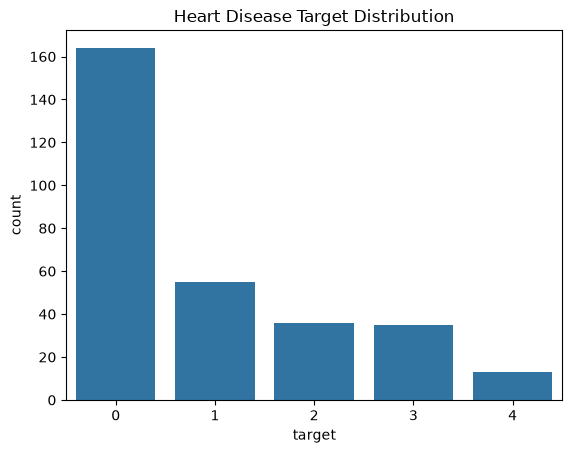

In [8]:
#Visualize the target variable 

sns.countplot(x='target', data=df)
plt.title("Heart Disease Target Distribution")
plt.show()


In [9]:
#target ranges from 0 to 4 with 0meaining no heart desease and 1 meaning heart disease
df['target'] = (df['target'] > 0).astype(int)


In [10]:
#Split the dataset into training and testing sets to avoid data leak

X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)


Training shape: (212, 13)
Testing shape: (91, 13)


In [11]:
#Handle missing values. verify teh categorical and numerical variables

numerical_cols = [
    'age', 'trestbps', 'chol',
    'thalach', 'oldpeak'
]

categorical_cols = [
    'sex', 'cp', 'fbs', 'restecg',
    'exang', 'slope', 'ca', 'thal'
]

print("Numerical:", numerical_cols)
print("Categorical:", categorical_cols)


Numerical: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Categorical: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


In [12]:
#handle the missing values
missing_percent = X_train.isnull().mean() * 100

print(missing_percent)

drop_cols = missing_percent[
    missing_percent > 50
].index.tolist()

X_train = X_train.drop(columns=drop_cols)
X_test = X_test.drop(columns=drop_cols)

numerical_cols = [
    c for c in numerical_cols if c not in drop_cols
]
categorical_cols = [
    c for c in categorical_cols if c not in drop_cols
]

print("Dropped columns:", drop_cols)


age         0.000000
sex         0.000000
cp          0.000000
trestbps    0.000000
chol        0.000000
fbs         0.000000
restecg     0.000000
thalach     0.000000
exang       0.000000
oldpeak     0.000000
slope       0.000000
ca          0.000000
thal        0.471698
dtype: float64
Dropped columns: []


In [13]:
#create imputers for mssing values

num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='most_frequent')


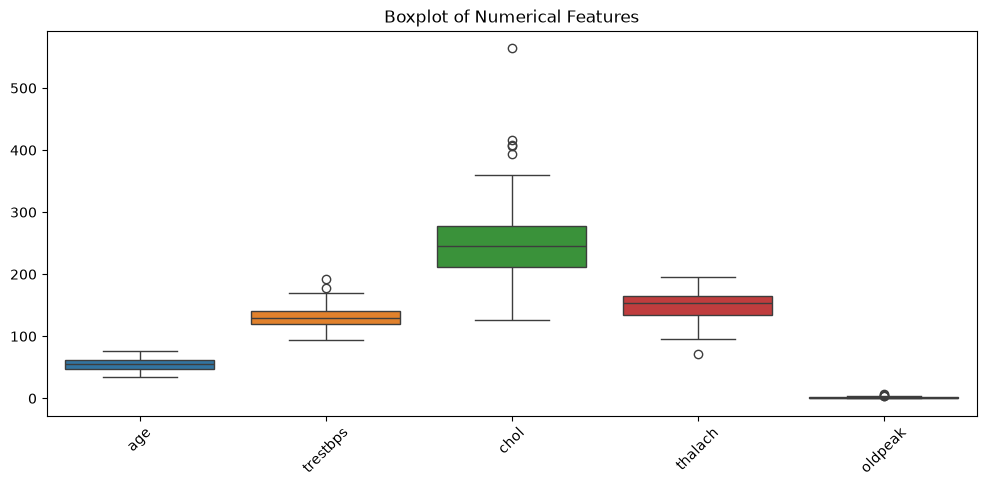

In [14]:
#Visualize outliers using box plot

plt.figure(figsize=(12, 5))

sns.boxplot(data=X_train[numerical_cols])

plt.title("Boxplot of Numerical Features")
plt.xticks(rotation=45)
plt.show()


In [15]:
#Cap outliers at the 95th percentile

# Calculate 95th percentile from training data
upper_limits = X_train[numerical_cols].quantile(0.95)

# Cap training and testing data
X_train[numerical_cols] = X_train[numerical_cols].clip(
    upper=upper_limits, axis=1
)

X_test[numerical_cols] = X_test[numerical_cols].clip(
    upper=upper_limits, axis=1
)

print("95th percentile thresholds:")
print(upper_limits)


95th percentile thresholds:
age          68.00
trestbps    160.00
chol        332.25
thalach     180.45
oldpeak       3.00
Name: 0.95, dtype: float64


In [16]:
#handle categorical variables

encoder = OneHotEncoder(
    handle_unknown='ignore'
)


**Create a complete preprocessing pipeline**

In [17]:
# Numerical preprocessing
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer([
    ('num', num_pipeline, numerical_cols),
    ('cat', cat_pipeline, categorical_cols)
])

# Fit on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply same preprocessing to testing data
X_test_processed = preprocessor.transform(X_test)

print("Training processed:", X_train_processed.shape)
print("Testing processed:", X_test_processed.shape)


Training processed: (212, 28)
Testing processed: (91, 28)


In [18]:
#Convert the processed data back to DataFrames

feature_names = preprocessor.get_feature_names_out()

X_train_final = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_final = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Final training dataset:")
display(X_train_final.head())

print("Missing values in training data:",
      X_train_final.isnull().sum().sum())

print("Missing values in testing data:",
      X_test_final.isnull().sum().sum())


Final training dataset:


,num__age,num__trestbps,num__chol,num__thalach,num__oldpeak,cat__sex_0.0,cat__sex_1.0,cat__cp_1.0,cat__cp_2.0,cat__cp_3.0,...,cat__slope_1.0,cat__slope_2.0,cat__slope_3.0,cat__ca_0.0,cat__ca_1.0,cat__ca_2.0,cat__ca_3.0,cat__thal_3.0,cat__thal_6.0,cat__thal_7.0
230,-0.284227,0.412022,-1.095954,0.912066,-0.879504,1.0,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
43,0.526912,1.316520,-0.750841,0.353773,0.687344,0.0,1.0,0.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
283,-2.254135,-0.492476,-1.182233,1.144689,-0.983961,0.0,1.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
206,0.411035,-0.104834,0.262930,-0.902388,2.149735,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
42,1.569805,1.962590,1.190423,0.586395,-0.566135,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0


Missing values in training data: 0
Missing values in testing data: 0


In [19]:
#verify final dataset

print("Original dataset:", df.shape)

print("Training features:", X_train_final.shape)
print("Testing features:", X_test_final.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("Target classes:", y_train.unique())


Original dataset: (303, 14)
Training features: (212, 28)
Testing features: (91, 28)
Training target: (212,)
Testing target: (91,)
Target classes: [0 1]


**Save the preprocessed datasets**

In [20]:
train_final = X_train_final.copy()
train_final['target'] = y_train

test_final = X_test_final.copy()
test_final['target'] = y_test

train_final.to_csv("heart_train_processed.csv", index=False)
test_final.to_csv("heart_test_processed.csv", index=False)

print("Preprocessed datasets saved successfully!")


Preprocessed datasets saved successfully!
